### Основы машинного обучения
### Простая регрессионная модель
1. Загрузка и первичный анализ данных
2. Предварительная обработка данных
3. Выбор признаков (X) и целевой переменной (y)
4. Разделение выборки на обучающую и тестовую
5. Обучение модели
6. Получение предсказаний и оценка качества
7. Анализ результата, коэффициентов модели

### Задача:
0. Установить библиотеку scikit-learn
1. Скачать данные с Kaggle
2. Сделать модель линейное регрессии по алгоритму

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df_raw = pd.read_csv(
    '../data/raw/insurance.csv',
    dtype = {
        "sex":"category",
        "smoker":"category",
        "region":"category",
    }
)

In [5]:
df_raw

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       1338 non-null   int64   
 1   sex       1338 non-null   category
 2   bmi       1338 non-null   float64 
 3   children  1338 non-null   int64   
 4   smoker    1338 non-null   category
 5   region    1338 non-null   category
 6   charges   1338 non-null   float64 
dtypes: category(3), float64(2), int64(2)
memory usage: 46.2 KB


In [10]:
df_raw.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [13]:
df_raw.duplicated().sum()

np.int64(1)

In [14]:
df_raw[df_raw.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [15]:
df_raw[df_raw['charges']==1639.5631]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [17]:
df_raw = df_raw.drop_duplicates()

In [18]:
df_raw.duplicated().sum()

np.int64(0)

In [19]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       1337 non-null   int64   
 1   sex       1337 non-null   category
 2   bmi       1337 non-null   float64 
 3   children  1337 non-null   int64   
 4   smoker    1337 non-null   category
 5   region    1337 non-null   category
 6   charges   1337 non-null   float64 
dtypes: category(3), float64(2), int64(2)
memory usage: 56.5 KB


In [20]:
df_raw[df_raw['charges']==1639.5631]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631


In [22]:
df_raw['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [23]:
df_raw['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [24]:
df_raw['region'].value_counts()

region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

In [28]:
df_processed = pd.get_dummies(
    df_raw, 
    columns=['sex', 'smoker', 'region'], 
    drop_first=True,
)

In [29]:
df_processed

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False
...,...,...,...,...,...,...,...,...,...
1333,50,30.970,3,10600.54830,True,False,True,False,False
1334,18,31.920,0,2205.98080,False,False,False,False,False
1335,18,36.850,0,1629.83350,False,False,False,True,False
1336,21,25.800,0,2007.94500,False,False,False,False,True


In [30]:
df_processed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1337 non-null   int64  
 1   bmi               1337 non-null   float64
 2   children          1337 non-null   int64  
 3   charges           1337 non-null   float64
 4   sex_male          1337 non-null   bool   
 5   smoker_yes        1337 non-null   bool   
 6   region_northwest  1337 non-null   bool   
 7   region_southeast  1337 non-null   bool   
 8   region_southwest  1337 non-null   bool   
dtypes: bool(5), float64(2), int64(2)
memory usage: 58.8 KB


In [31]:
y = df_processed['charges']

In [32]:
X = df_processed.drop('charges', axis=1)

In [33]:
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1337, dtype: float64

In [34]:
X

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,False,True,False,False,True
1,18,33.770,1,True,False,False,True,False
2,28,33.000,3,True,False,False,True,False
3,33,22.705,0,True,False,True,False,False
4,32,28.880,0,True,False,True,False,False
...,...,...,...,...,...,...,...,...
1333,50,30.970,3,True,False,True,False,False
1334,18,31.920,0,False,False,False,False,False
1335,18,36.850,0,False,False,False,True,False
1336,21,25.800,0,False,False,False,False,True


In [35]:
y.shape

(1337,)

In [36]:
X.shape

(1337, 8)

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=567567
)

In [41]:
X_train

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
133,19,25.555,0,True,False,True,False,False
1087,57,31.540,0,True,False,True,False,False
467,56,33.820,2,False,False,True,False,False
721,53,36.600,3,True,False,False,False,True
854,49,23.845,3,False,True,False,False,False
...,...,...,...,...,...,...,...,...
737,26,23.700,2,True,False,False,False,True
317,54,32.775,0,True,False,False,False,False
1198,40,29.355,1,True,False,True,False,False
1113,28,26.315,3,False,False,True,False,False


In [42]:
X_test

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
1040,35,28.025,0,False,True,True,False,False
626,36,28.880,3,True,False,False,False,False
572,30,43.120,2,False,False,False,True,False
357,47,29.830,3,True,False,True,False,False
988,34,34.675,0,True,False,False,False,False
...,...,...,...,...,...,...,...,...
688,47,24.100,1,False,False,False,False,True
908,63,39.800,3,True,False,False,False,True
44,38,37.050,1,True,False,False,False,False
516,20,35.310,1,True,False,False,True,False


In [43]:
y_train

133      1632.56445
1087    11353.22760
467     12643.37780
721     11264.54100
854     24106.91255
           ...     
737      3484.33100
317     10435.06525
1198     6393.60345
1113     5312.16985
363      2597.77900
Name: charges, Length: 1069, dtype: float64

In [44]:
y_test

1040    20234.85475
626      6748.59120
572      4753.63680
357      9620.33070
988      4518.82625
           ...     
688     26236.57997
908     15170.06900
44       6079.67150
516     27724.28875
780     18259.21600
Name: charges, Length: 268, dtype: float64

In [45]:
model = LinearRegression()

In [46]:
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [48]:
predictions = model.predict(X_test)

In [49]:
predictions

array([29953.95048528,  8678.90969932, 10359.40894577, 11739.10388503,
        8609.04553805,  9514.22960761,  3808.39394963,  3723.1301739 ,
       12891.14962653, 23716.43626985,  5503.62407567,  2342.80843622,
        9197.69597253,  6440.80830242,  7365.76016219,  4883.14366014,
       15475.10547496, 12114.49582982,  4508.12679645, 39334.06311697,
       10664.16673297, 10707.21712495,  9640.5745791 ,  7406.55016868,
        6817.15781602,  7029.04103631,  1966.31019163, 31622.40262887,
       12625.69278462,  2105.62118046, 12479.14107687,  6873.7569949 ,
        5714.05118214, 16041.75260312,  3691.30856201, 17715.73966944,
       33475.21897988,  2300.21340805, 28712.03135424, 14651.27325112,
        5188.75621622,  -172.76471689, 26974.37962307, 26148.37611757,
        6200.77069207, 11666.65228001, 34632.42756969,  6441.89416426,
       12730.47075866, 15657.52579408, 39075.0822193 ,  4546.23757228,
       10806.13625769,  8016.24077518,  5174.31026945,  8666.25097604,
      

In [50]:
mae = mean_absolute_error(y_test, predictions)

In [51]:
mse = mean_squared_error(y_test, predictions)

In [52]:
rmse = np.sqrt(mse)

In [53]:
r2 = r2_score(y_test, predictions)

In [65]:
df_processed['charges'].describe()

count     1337.000000
mean     13279.121487
std      12110.359656
min       1121.873900
25%       4746.344000
50%       9386.161300
75%      16657.717450
max      63770.428010
Name: charges, dtype: float64

In [61]:
print(f"""
Метрики качества:
MAE: {mae:.2f}
RMSE: {rmse:.2f}
R^2: {r2:.2f}
""")


Метрики качества:
MAE: 4139.54
RMSE: 5936.79
R^2: 0.77



In [66]:
coeffs = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])

In [67]:
coeffs

,Coefficient
age,257.927296
bmi,346.461598
children,520.584844
sex_male,-40.790006
smoker_yes,23456.301860
region_northwest,-106.144586
region_southeast,-1225.755303
region_southwest,-1300.012199


In [68]:
model.intercept_

np.float64(-12133.248435336249)

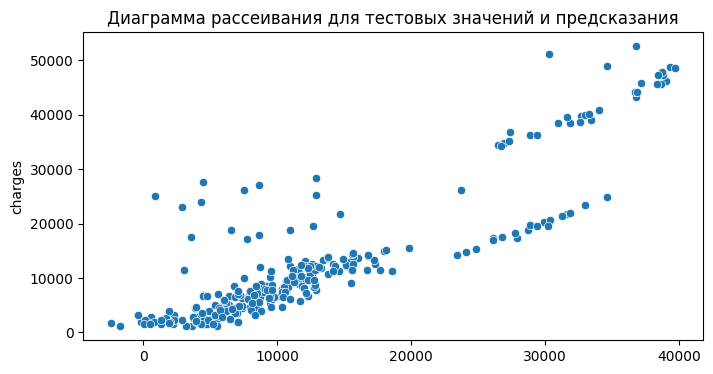

In [74]:
plt.figure(figsize=(8,4)) # Размер графика
plt.title('Диаграмма рассеивания для тестовых значений и предсказания') # Заголовок
ax = sns.scatterplot(
    x=predictions,
    y=y_test,
)
plt.show()